In [5]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'  # убирает системное предупреждение joblib в Windows при запуске KMeans
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from scipy.stats import chi2_contingency, pointbiserialr, skew
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings("ignore")
from sklearn.metrics import classification_report, roc_auc_score
import time
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_validate


# 1. Описание датасета и решаемой задачи

Я выбрала датасет telco customer churn - Отток клиентов телекоммуникационных компаний.

Он включает следующую информацию:

1. Клиенты, ушедшие в течение последнего месяца - столбец называется Churn
2. Услуги, на которые подписан каждый клиент - телефон, несколько линий, интернет, онлайн-безопасность, онлайн-резервное копирование, защита устройств, техническая поддержка, а также потоковое телевидение и фильмы.
3. Информация об учетной записи клиента - как долго он является клиентом, договор, способ оплаты, электронный счет, ежемесячные платежи и общая сумма платежей
4. Демографические данные о клиентах - пол, возраст, наличие партнеров и иждивенцев

Перед нами стоит задача классификации. Мы должны определить, откажется ли клиент от услуг компании или нет

# 2. Предварительный анализ и очистка данных

Загружаем датасет.

In [6]:
data = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.DataFrame(data)
df_orig = df.copy()    # нетронутая копия исходных данных, чтобы смотреть на значения до преобразований
df_change = df.copy()  # копия для графиков в разделе 4: на ней категории остаются словами (Yes/No и т.д.), а не числами после энкодинга
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Каждая строка представляет клиента, каждый столбец содержит атрибуты клиента

Приведем информацию о физическом смысле каждого атрибута данных. Представим, насколько значимыми они будут для предсказания целевой переменной. Пока все основывается на предположениях, а позже найдем корреляцию между признаками и целевой переменной.

| Признак            | Описание                                                                                 | Пример влияния на отток                                            | Значимость      |
|--------------------|------------------------------------------------------------------------------------------|--------------------------------------------------------------------|-----------------|
| `customerID`       | Уникальный идентификатор клиента                                                         | Не используется в модели                                           | Низкая (идентификатор) |
| `gender`           | Пол клиента (`Male`/`Female`)                                                            | Практически не влияет                                              | Низкая          |
| `SeniorCitizen`    | Флаг пожилого клиента (1 = возраст ≥ 65)                                                  | Пожилые могут по‑разному относиться к услугам                      | Средняя         |
| `Partner`          | Наличие партнера в семье (`Yes`/`No`)                                                    | Семейные обязательства обычно снижают отток                        | Средняя         |
| `Dependents`       | Наличие иждивенцев (`Yes`/`No`)                                                          | Аналогично `Partner`                                               | Средняя         |
| `tenure`           | Срок обслуживания в месяцах                                                         | Чем дольше клиент, тем меньше вероятность ухода                    | Высокая         |
| `PhoneService`     | Наличие телефонной услуги (`Yes`/`No`)                                                   | Базовая услуга                         | Низкая          |
| `MultipleLines`    | Несколько телефонных линий (`Yes`/`No`/`No phone service`)                              | Дополнительные линии могут удерживать                              | Средняя         |
| `InternetService`  | Тип доступа в интернет (`DSL`/`Fiber optic`/`No`)                                        | Вероятно, многим без разницы                    | Низкая         |
| `OnlineSecurity`   | Услуга «Онлайн‑безопасность» (`Yes`/`No`/`No internet service`)                         | Снижает отток                                                      | Средняя         |
| `OnlineBackup`     | Услуга «Резервное копирование» (`Yes`/`No`/`No internet service`)                        | Умеренно удерживает                                                | Средняя         |
| `DeviceProtection` | Защита устройств (`Yes`/`No`/`No internet service`)                                      | Поддержка устройств удерживает                                    | Средняя         |
| `TechSupport`      | Техподдержка 24×7 (`Yes`/`No`/`No internet service`)                                     | Сильный фактор удержания                                          | Высокая         |
| `StreamingTV`      | Услуга стриминга ТВ (`Yes`/`No`/`No internet service`)                                   | Умеренный фактор                                                  | Средняя         |
| `StreamingMovies`  | Услуга стриминга фильмов (`Yes`/`No`/`No internet service`)                              | Умеренный фактор                                                  | Средняя         |
| `Contract`         | Тип контракта (`Month-to-month`/`One year`/`Two year`)                                   | Месячный контракт - это наибольший риск оттока           | Высокая         |
| `PaperlessBilling` | Безналичная оплата (`Yes`/`No`)                                                          | Немного снижает риск ухода, ведь это удобно                                      | Средняя         |
| `PaymentMethod`    | Способ оплаты (`Electronic check`/`Mailed check`/`Bank transfer`/`Credit card`)          | Вряд ли это влияет на отток                         | Низкая         |
| `MonthlyCharges`   | Ежемесячный платеж в долларах                                                             | Чем выше платеж, тем выше риск оттока                             | Высокая         |
| `TotalCharges`     | Суммарные начисления за всё время                                                         | Аналогично `MonthlyCharges`                                 | Высокая         |
| `Churn`            | Целевая переменная (отток: `Yes`/`No`) Клиент ушел? Да или нет |

Перейдем к анализу данных. Выведем описание категориальных признаков

In [7]:
df_orig.describe(include=['O'])

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


взглянув на первые строки датасета, можно заметить, что численных столбцов у нас всего 3:
1. tenure (кол-во месяцев, сколько клиент пользуется услугами компании)
2. MonthlyCharges (сумма уплаченная клиентом в течение месяца)
3. TotalCharges (сумма уплаченная всего)

однако описание говорит о том, что TotalCharges вообще не является численным столбцом, а SeniorCitizen (является ли клиент пожилым) - считается численным. Отчетливо видно, что это категориальный признак, и в дальнейшем для правильной работы модели нам и потребуется переводить категориальные признаки в численные (в данном случае 0/1). Но пока для удобства восприятия информации только реально количественные будут иметь тип int или float

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Переведем SeniorCitizen из численного в категориальный, а TotalCharges наоборот

In [10]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   object 
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Посмотрим что получилось:

In [12]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Появились пропуски в столбце TotalCharges, взглянем на них

In [13]:
df['TotalCharges'].isnull().sum()

11

In [14]:
print(df[df['TotalCharges'].isna()][['customerID','tenure','MonthlyCharges','TotalCharges']])

      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           NaN
753   3115-CZMZD       0           20.25           NaN
936   5709-LVOEQ       0           80.85           NaN
1082  4367-NUYAO       0           25.75           NaN
1340  1371-DWPAZ       0           56.05           NaN
3331  7644-OMVMY       0           19.85           NaN
3826  3213-VVOLG       0           25.35           NaN
4380  2520-SGTTA       0           20.00           NaN
5218  2923-ARZLG       0           19.70           NaN
6670  4075-WKNIU       0           73.35           NaN
6754  2775-SEFEE       0           61.90           NaN


Видимо пропуски появились после того, как мы преобразовали тип данных в TotalCharges. Какие-то из значений в этом столбце не являлись числами, и при преобразовании в числовой тип данных они стали NaN. Получается, что изначально значения TotalCharges там, где tenure = 0 были заполнены чем-то другим, пробелом или, может, прочерком

In [15]:
df_orig.loc[df['tenure'] == 0, 'TotalCharges'].head(10).tolist()

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Пропущенных значений всего 11, удалим их

In [16]:
df.dropna(inplace=True)

Кроме этих явных пропусков заметим, что есть еще и много значений типа 'No internet service'. Нужно решить, оставлять ли такие значения как есть, действительно считать за пропуск или что-то еще с ними сделать. Посмотрим какую долю данных эти значения в принципе занимают

OnlineSecurity
No                     49.73
Yes                    28.65
No internet service    21.62
Name: proportion, dtype: float64

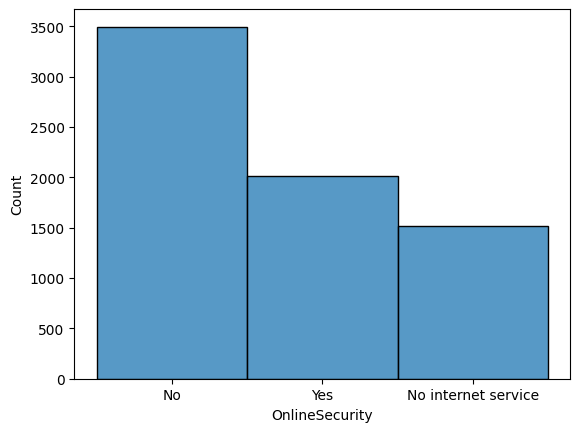

In [17]:
sns.histplot(data=df, x="OnlineSecurity")
(df['OnlineSecurity'].value_counts(normalize=True) * 100).round(2)

MultipleLines
No                  48.14
Yes                 42.19
No phone service     9.67
Name: proportion, dtype: float64

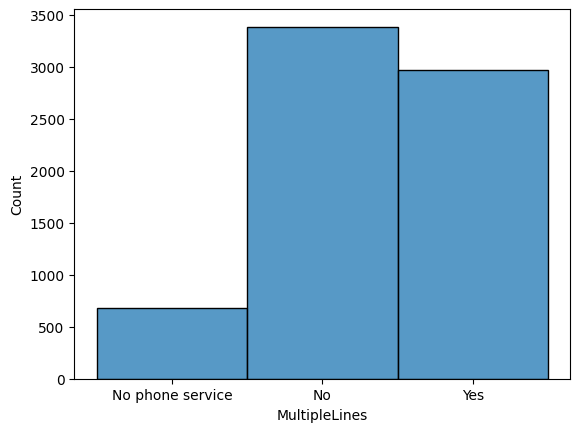

In [18]:
sns.histplot(data=df, x="MultipleLines")
(df['MultipleLines'].value_counts(normalize=True) * 100).round(2)

Значения 'No internet service' и 'No phone service' занимают 20% и 10% процентов соответственно. Это далеко не редкие категории и, внимательнее рассмотрев даже начало таблицы, можно понять, что по своей сути они имеют смысл для модели и просто так убрать их или заменить на просто 'No' мы не можем. Однако стоило обратить внимание на другие связанные с этими 'No internet service' и 'No phone service' столбцы. Нужно проверить наши данные на избыточность. Конечно, позже мы будем чистить данные от избыточных, но сейчас проверим их потому, что это бросилось в глаза, да и больше очевидной избыточности пока нет.

In [19]:
df[['PhoneService', 'MultipleLines']].head(6)

,PhoneService,MultipleLines
0,No,No phone service
1,Yes,No
2,Yes,No
3,No,No phone service
4,Yes,No
5,Yes,Yes


Итак, посмотрим на эти столбцы. Из MultipleLines можно однозначно восстановить PhoneService:

MultipleLines == 'No phone service' => PhoneService = No

Иначе ('No' или 'Yes') => PhoneService = Yes

Поэтому столбец PhoneService избыточен и его можно смело удалить. Убедимся, правдива ли эта догадка и если да, удалим столбец:

In [20]:
inferred = df['MultipleLines'].apply(lambda x: 'No' if x == 'No phone service' else 'Yes')

if (df['PhoneService'] == inferred).all():
    print("Да, удаляем")
else:
    print("Нет, есть расхождения")

Да, удаляем


Также удалим CustomerID, так как это просто бесполезный идентификатор

In [21]:
df.drop(columns=['PhoneService', 'customerID'], inplace=True)

Однако в отличие от пары PhoneService и MultipleLines, никакой один сервис-столбец не кодирует полностью информацию об InternetService, и наоборот. Если InternetService = No, то все дочерние сервис-столбцы (OnlineSecurity, OnlineBackup и т. д.) будут иметь значение "No internet service". Но если InternetService ∈ {DSL, Fiber optic}, то дочерние колонки могут быть как Yes, так и No. При этом, например, OnlineSecurity = No не говорит, подключен ли клиент к интернету вообще, он может иметь InternetService = No или DSL/Fiber optic.

Таким образом, на этом этапе больше колонок, однозначно восстанавливающих другие, нет

Также возьмем стобец tenure (срок обслуживания в месяцах) и разобъем его значения на несколько групп. Здесь максимальное значение 72 и поэтому будет очень удобно разбить как раз на сроки до 6 лет. При этом исходный столбец tenure тоже оставим: группы удобны для анализа и графиков, но при разбиении теряется информация (клиент со сроком 1 месяц и клиент со сроком 11 месяцев попадают в одну группу), а срок обслуживания - один из самых важных признаков для предсказания оттока.

In [22]:
bins = [0, 12, 24, 48, 72]
labels = ['<1 year','1–2 years','2–4 years','4–6 years']
df['tenure_group'] = pd.cut(df['tenure'], bins=bins, labels=labels, right=True, include_lowest=True)
df['tenure_group'].value_counts(normalize=True).round(2) * 100

tenure_group
4–6 years    32.0
<1 year      31.0
2–4 years    23.0
1–2 years    15.0
Name: proportion, dtype: float64

In [23]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7032.0,32.421786,24.545260,1.00,9.0000,29.000,55.0000,72.00
MonthlyCharges,7032.0,64.798208,30.085974,18.25,35.5875,70.350,89.8625,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.4500,1397.475,3794.7375,8684.80


In [24]:
df.describe(include=['O'])

,gender,SeniorCitizen,Partner,Dependents,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
count,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032,7032
unique,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,2
top,Male,No,No,No,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
freq,3549,5890,3639,4933,3385,3096,3497,3087,3094,3472,2809,2781,3875,4168,2365,5163


Теперь в данных нет пропусков и все данные столбцов соответствуют нужным типам

# 3. Преобразование атрибутов в числовые признаки, encoding

Дальше мы преобразуем все оставшиеся признаки в числовой формат

In [25]:
df.dtypes

gender                object
SeniorCitizen         object
Partner               object
Dependents            object
tenure                 int64
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
Churn                 object
tenure_group        category
dtype: object

Сейчас мы видим и object, и category, но по итогу должны остаться только числовые данные

Сначала преобразуем бинарные признаки с помощью простого LabelEncoding через map, чтобы сразу получить 0/1 без лишних объектов и преобразований. Помимо этого LabelEncoding здесь подойдет и для преобразования столбцов tenure_group и Contract. Tenure_group это время обслуживания в группах по годам (<1 year, 1–2 years, 2–4 years, 4–6 years). Contract принимает значения Month-to-month, One year и Two year, то есть договор об оказании услуг может быть подписан всего на месяц, на год или на два.

Мы можем поставить эти группы по возрастанию и присвоить соответствующие значения: <1 года - 0, 1-2 года - 1 и т. д., а также Month-to-month - 0, One year - 1, Two year - 2. Все потому, что LabelEncoding учитывает порядок, который нам и нужен в случае с годами и с длительностью договора


In [26]:
binary_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PaperlessBilling']
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
for col in ['SeniorCitizen', 'Partner', 'Dependents', 'PaperlessBilling']:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df['tenure_group'] = df['tenure_group'].map({'<1 year': 0, '1–2 years': 1, '2–4 years': 2, '4–6 years': 3})
df['Contract'] = df['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})

Преобразуем и мультикатегориальные признаки с помощью One-Hot Encoding. Он не учитывает порядок как шкалу, поэтому создает дополнительные столбцы, которые содержат либо 0, либо 1. Таким образом мы получим по 3 новых dummy-столбца на каждый старый столбец после энкодинга. Но чтобы не получить чересчур большое количество признаков, которые будут еще и восстанавливать некоторые столбцы по себе же, сразу используем drop_first=True

In [27]:
multi_cols = [
    'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'InternetService', 'PaymentMethod'
]
df = pd.get_dummies(df, columns=multi_cols, drop_first=True)

df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,No,...,False,False,False,False,False,False,False,False,True,False
1,1,0,0,0,34,1,0,56.95,1889.50,No,...,False,False,False,False,False,False,False,False,False,True
2,1,0,0,0,2,0,1,53.85,108.15,Yes,...,False,False,False,False,False,False,False,False,False,True
3,1,0,0,0,45,1,0,42.30,1840.75,No,...,True,False,False,False,False,False,False,False,False,False
4,0,0,0,0,2,0,1,70.70,151.65,Yes,...,False,False,False,False,False,True,False,False,True,False


In [28]:
df.dtypes

gender                                      int64
SeniorCitizen                               int64
Partner                                     int64
Dependents                                  int64
tenure                                      int64
Contract                                    int64
PaperlessBilling                            int64
MonthlyCharges                            float64
TotalCharges                              float64
Churn                                      object
tenure_group                             category
MultipleLines_No phone service               bool
MultipleLines_Yes                            bool
OnlineSecurity_No internet service           bool
OnlineSecurity_Yes                           bool
OnlineBackup_No internet service             bool
OnlineBackup_Yes                             bool
DeviceProtection_No internet service         bool
DeviceProtection_Yes                         bool
TechSupport_No internet service              bool


In [29]:
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1}).astype(int)

df['tenure_group'] = df['tenure_group'].cat.codes
bool_cols = df.select_dtypes('bool').columns
df[bool_cols] = df[bool_cols].astype(int)

df.dtypes


gender                                     int64
SeniorCitizen                              int64
Partner                                    int64
Dependents                                 int64
tenure                                     int64
Contract                                   int64
PaperlessBilling                           int64
MonthlyCharges                           float64
TotalCharges                             float64
Churn                                      int32
tenure_group                                int8
MultipleLines_No phone service             int32
MultipleLines_Yes                          int32
OnlineSecurity_No internet service         int32
OnlineSecurity_Yes                         int32
OnlineBackup_No internet service           int32
OnlineBackup_Yes                           int32
DeviceProtection_No internet service       int32
DeviceProtection_Yes                       int32
TechSupport_No internet service            int32
TechSupport_Yes     

In [30]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,InternetService_Fiber optic,InternetService_No,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,0,0,0,0,1
2,1,0,0,0,2,0,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,1,0,42.30,1840.75,0,...,1,0,0,0,0,0,0,0,0,0
4,0,0,0,0,2,0,1,70.70,151.65,1,...,0,0,0,0,0,1,0,0,1,0


In [31]:
df.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
gender,7032.0,0.504693,0.500014,0.00,0.0000,1.000,1.0000,1.00
SeniorCitizen,7032.0,0.162400,0.368844,0.00,0.0000,0.000,0.0000,1.00
Partner,7032.0,0.482509,0.499729,0.00,0.0000,0.000,1.0000,1.00
Dependents,7032.0,0.298493,0.457629,0.00,0.0000,0.000,1.0000,1.00
tenure,7032.0,32.421786,24.545260,1.00,9.0000,29.000,55.0000,72.00
Contract,7032.0,0.688567,0.832934,0.00,0.0000,0.000,1.0000,2.00
PaperlessBilling,7032.0,0.592719,0.491363,0.00,0.0000,1.000,1.0000,1.00
MonthlyCharges,7032.0,64.798208,30.085974,18.25,35.5875,70.350,89.8625,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.4500,1397.475,3794.7375,8684.80
Churn,7032.0,0.265785,0.441782,0.00,0.0000,0.000,1.0000,1.00


Теперь все признаки выраженны численно. Можно идти дальше

# 4. Описательный анализ данных

Вспомним шкалы измерения каждого признака. У нас есть три количественных столбца:
- Непрерывные количественные - MonthlyCharges и TotalCharges, то есть ежемесячный платеж в долларах и суммарные начисления за все время
- Дискретный количественный - tenure, срок обслуживания в месяцах (от 0 до 72)

И два порядковых категориальных признака
- tenure_group (int: 0 - 3) - группы по длительности обслуживания (<1 г, 1-2 г, 2-4 г, 4-6 г)
- Contract (int 0 - 2) - тип договора (на месяц, на год, на два года)

Остальные категориальные признаки имеют по три категории (Yes/No/No service). Это MultipleLines, InternetService и все дочерние сервисы (OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies). Мы не удаляли No service, поскольку он встречается у значительной доли клиентов и несет собственный смысл. После one-hot-encoding каждый из этих признаков разбит на два дамми-столбца

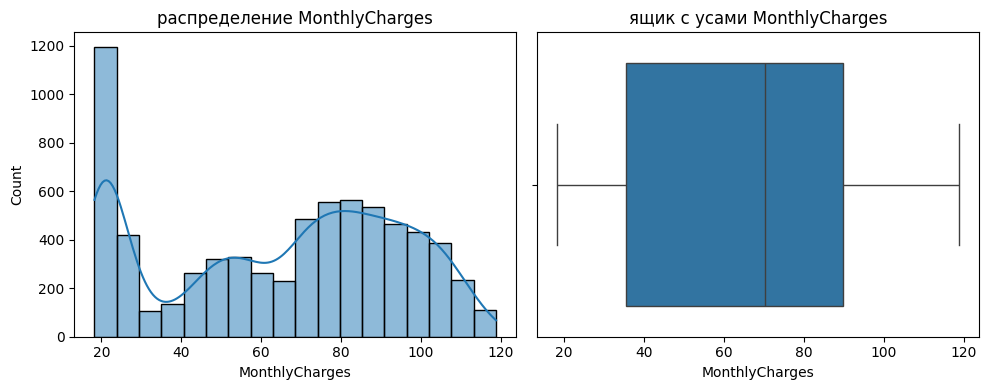

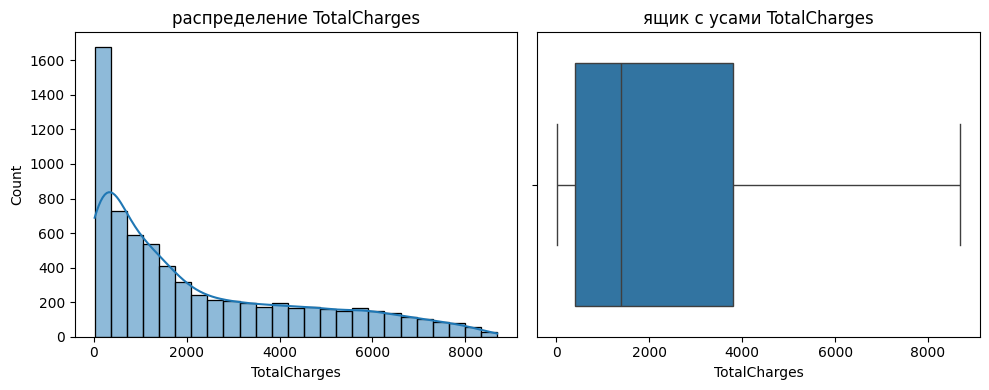

In [32]:
for col in ['MonthlyCharges','TotalCharges']:
    fig, ax = plt.subplots(1,2,figsize=(10,4))
    sns.histplot(df[col], kde=True, ax=ax[0])
    ax[0].set_title(f'распределение {col}')
    sns.boxplot(x=df[col], ax=ax[1])
    ax[1].set_title(f'ящик с усами {col}')
    plt.tight_layout()
    plt.show()

Построили распределение и ящик с усами для двух количественных переменных

Распределение MonthlyCharges не похоже на нормальное: виднеется высокий пик в районе 20 долларов. Это клиенты без интернета, которые пользуются только телефонной связью и поэтому платят мало (медианный платеж у них около 20 долларов). Остальные в среднем платят 60-80 долларов в месяц. Мы можем оставить такое распределение, оно вполне нормальное для настоящих данных, но перед обучением модели применим стандартизацию StandardScaler. Выбросов здесь нет.

А вот распределение переменной TotalCharges очень сильно смещено, видим длинный правый хвост. Значит, есть много новых клиентов, которые в целом мало отдали денег компании. Ящик с усами показывает медиану ближе к левому краю, а ус сильно уходит вправо. Лучше сделать такое распределение более симметричным. Применим несколько разных способов и посмотрим, что получится



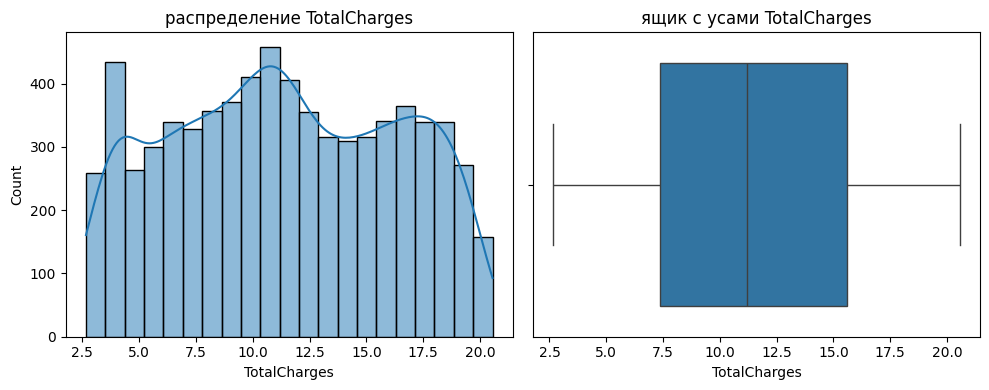

In [33]:
df['TotalCharges'] = np.cbrt(df['TotalCharges'])
fig, ax = plt.subplots(1,2,figsize=(10,4))
sns.histplot(df['TotalCharges'], kde=True, ax=ax[0])
ax[0].set_title('распределение TotalCharges')
sns.boxplot(x=df['TotalCharges'], ax=ax[1])
ax[1].set_title('ящик с усами TotalCharges')
plt.tight_layout()
plt.show()

Я попробовала нормализовать распределение с помощью log1p, sqrt, Box-Cox, но остановилась на cbrt - кубическом корне. Он сделал распределение наиболее симметричным. Распределение стало более сглаженным, чем-то похоже на нормальное или равномерное, но это уже гораздо лучше, чем было. Выбросов нет, для наших данных это отличный результат.

Дальше построим распределение признаков сразу совместное с целевой переменной Churn. Я взяла нашу таблицу до энкодинга, чтобы было легче воспринимать и интерпретировать информацию

In [34]:
bins = [0, 12, 24, 48, 72]
labels = ['<1 year','1–2 years','2–4 years','4–6 years']
df_change['tenure_group'] = pd.cut(df_change['tenure'], bins=bins, labels=labels, right=True, include_lowest=True)
df_change.drop('tenure', axis=1, inplace=True)
df_change['SeniorCitizen'] = df_change['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

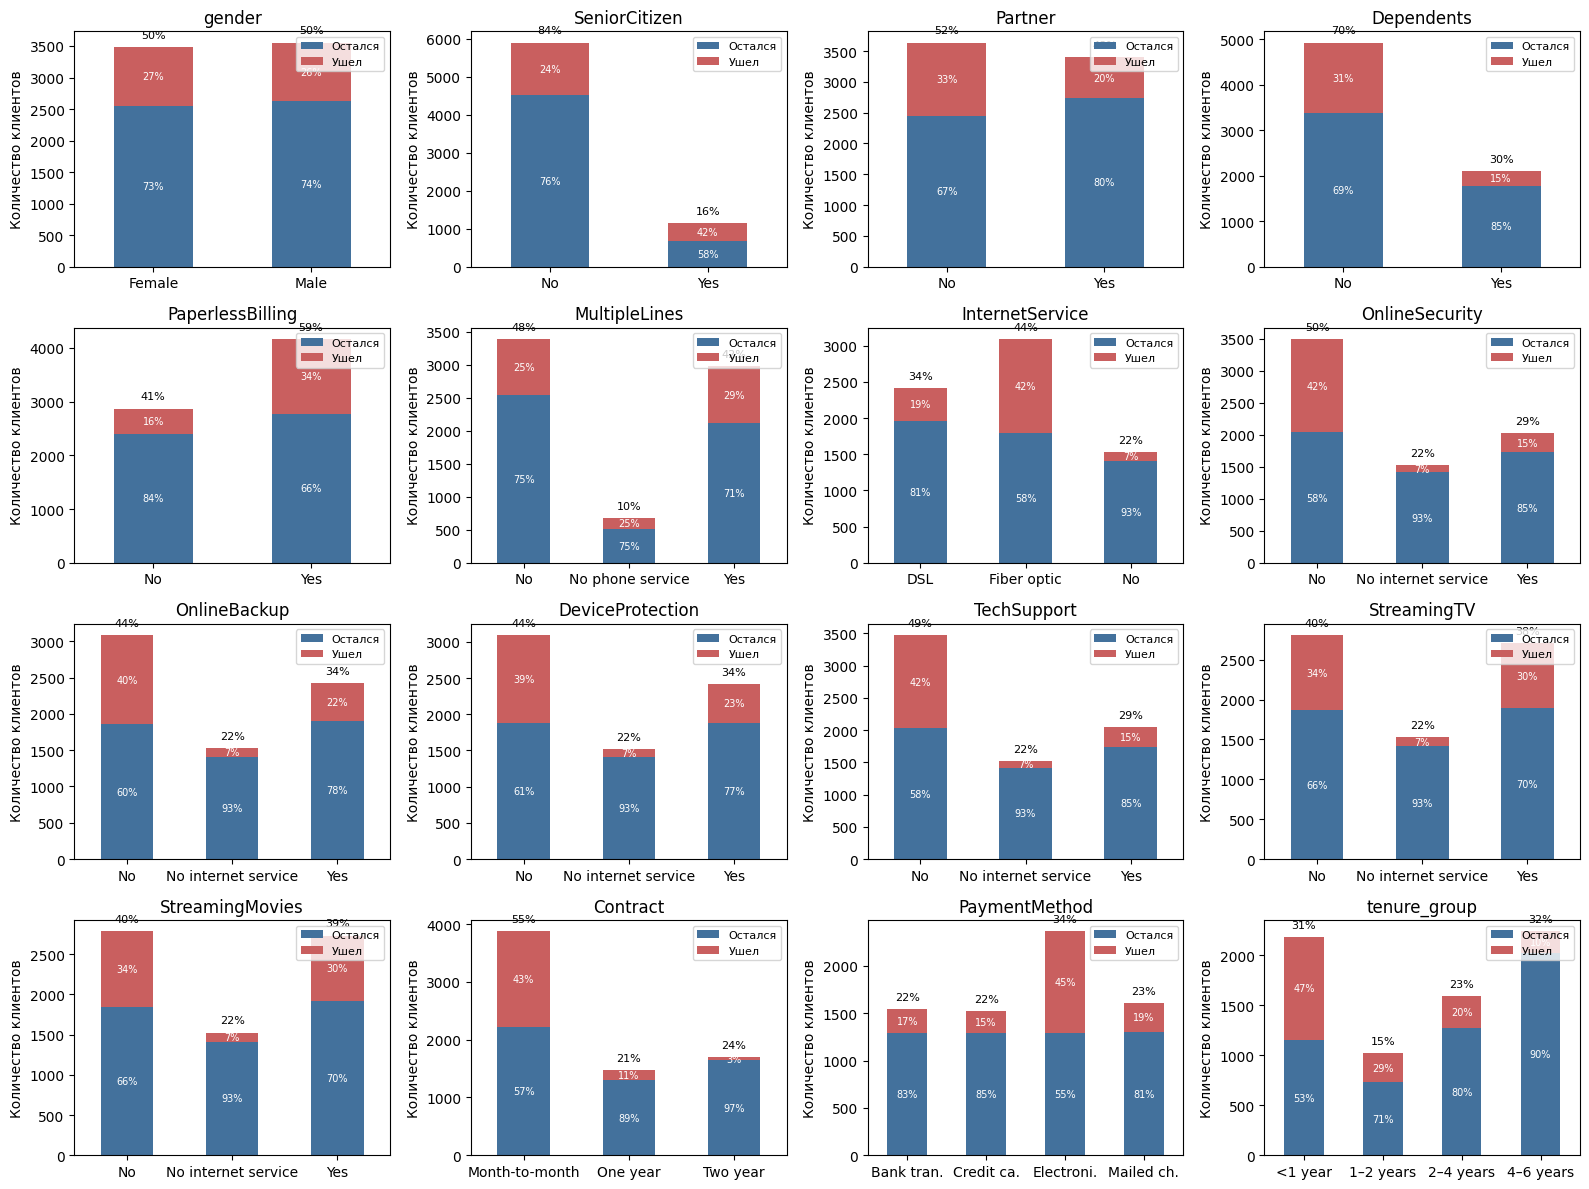

In [35]:
orig_cat_cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PaperlessBilling',
    'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaymentMethod', 'tenure_group'
]

n = len(orig_cat_cols)
ncols = 4
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*4, nrows*3))
axes = axes.flatten()
total = len(df_change)

for ax, col in zip(axes, orig_cat_cols):
    ct = pd.crosstab(df_change[col], df_change['Churn'])
    ct.plot(kind='bar', stacked=True, ax=ax, color=['#43719C','#C95F5F'], legend=False)

    ax.set_title(col)
    ax.set_ylabel('Количество клиентов')
    ax.set_xlabel('')
    ymin, ymax = ax.get_ylim()
    max_bar = ct.values.max()
    top_offset = ymax * 0.03

    for i, tot in enumerate(ct.sum(axis=1).values):
        pct_all = tot / total * 100
        ax.text(i, tot + top_offset,
                f'{pct_all:.0f}%', ha='center', va='bottom', fontsize=8)

    for i, (idx, row) in enumerate(ct.iterrows()):
        cum = 0
        for j, val in enumerate(row):
            pct_cat = val / row.sum() * 100
            height = val
            ax.text(i, cum + height/2,
                    f'{pct_cat:.0f}%',
                    ha='center', va='center', color='white', fontsize=7)
            cum += height

    ax.legend(['Остался','Ушел'], loc='upper right', fontsize=8)

    if col == 'PaymentMethod':
        labels = [lbl.get_text() for lbl in ax.get_xticklabels()]
        ax.set_xticklabels([lab[:9] + '.' for lab in labels], rotation=0)
    else:
        for lbl in ax.get_xticklabels():
            lbl.set_rotation(0)

for ax in axes[len(orig_cat_cols):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()



Пройдемся по признакам по порядку. От пола оказалось вообще мало что зависит: женщин и мужчин оказалось поровну и отказались они от услуг компании тоже поровну. Пожилых людей оказалось всего 16% от всех пользователей, и уходят пожилые гораздо чаще - 42% ушли. Наверное, это происходит из-за того, что старшее поколение не привыкло много платить за такие сервисы, да и денег у них бывает не так много, поэтому они готовы искать альтернативу. Людей с партнерами и без оказалось примерно одинаково, но чаще уходят те, у кого нет партнера. Пользователей без иждивенцев оказалось много - 70%, и уходят они примерно в два раза чаще, чем клиенты с иждивенцами. Также видим, что большинство людей - 60% получают электронные счета вместо бумажных (PaperlessBilling). При этом те, кто получает бумажные счета, уходят реже.

Также примерно поровну людей пользуются несколькими мобильными линиями. Те, кто пользуются услугами интернета, чаще всего выбирают оптоволокно, и они же чаще уходят. Большинство не подключают себе услугу онлайн-безопасности, защиты устройства, резервного сохранения информации и техподдержки и уходят. Зато те, кто пользуются ими, почти всегда остаются. Услуги ТВ и проката фильмов подключают поровну, и примерно 30% людей из тех, кто подключил и из тех, кто этого не сделал, уходят. И среди всех пользователей в среднем 20% людей вообще не пользуются услугами интернета.  

Вид договора очень сильно влияет на отток: половина всех пользователей оформляет месячный договор и из них целых 40% решают уйти. Это очевидно, ведь если бы человек планировал долго пользоваться услугами компании, он бы оформил договор на больший срок. Метод оплаты тоже оказался важным для определения оттока. Клиенты, расплачивающиеся «электронным чеком» вручную, уходят почти в три раза чаще, чем те, кто настроил автоматические списания. Наверное, так происходит потому, что автоматическая оплата удобнее и надежнее, она создает дополнительный барьер для ухода (надо отключать автоматическое продление, а не просто забыть оплатить), в то время как электронный чек - это разовый механизм: клиент получает счет и вручную решает, платить или нет. Ну и в конце концов, оказалось, что новых клиентов и тех, кто пользуется сервисами уже 4-6 лет поровну. И, конечно, новички уходят почти в половине случаев, ведь большинство сразу решает, нравится им или нет

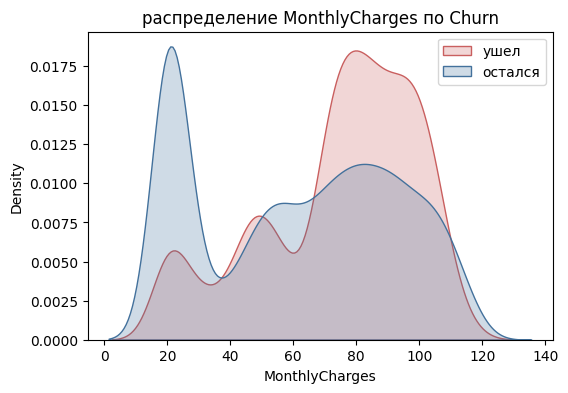

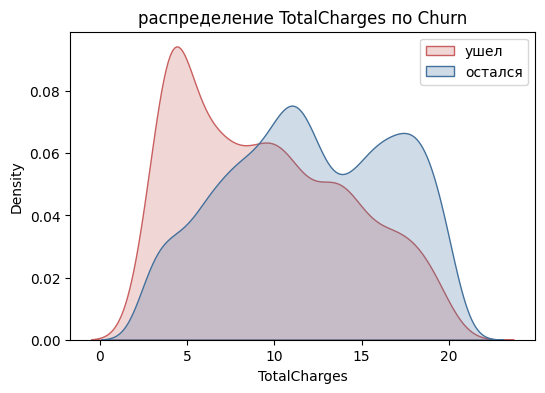

In [36]:
for col in ['MonthlyCharges','TotalCharges']:
    plt.figure(figsize=(6,4))
    sns.kdeplot(hue='Churn', data=df, x=col, fill=True, common_norm=0, palette=['#43719C', '#C95F5F'])
    plt.legend(labels=['ушел', 'остался'], loc='upper right')
    plt.title(f'распределение {col} по Churn')
    plt.show()

А здесь уже совместное распределение непрерывных переменных с целевой. Взглянув на первый график, можно понять, что что у большинства лояльных клиентов низкий ежемесячный платеж. Также уходят обычно те люди, у кому нужно платить больше, в районе 60-120 долларов. А второй график говорит о том, что здесь тоже низкие общие траты у новичков - сигнал оттока. А высокие - в принципе, признак удержания, потому что большими общие траты будут в основном у тех, кто уже долго остается с компанией

Теперь построим кореллограммы для наших признаков. Для количественных построим обычную матрицу корреляции Пирсона

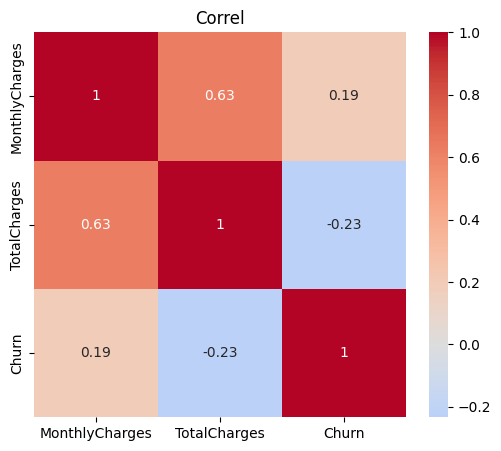

In [37]:
cont = ['MonthlyCharges','TotalCharges', 'Churn']
corr = df[cont].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Correl')
plt.show()

Видно, что признаки MonthlyCharges и TotalCharges умеренно коррелируют. Можно было бы как-то объединить эти признаки, но я считаю, что они несут разный, по-своему важный смысл и все нужно оставить как есть, тем более что связь между ними не слишком сильная

Теперь построим коррелограмму для категориальных признаков, у нас большинство из них бинарные. Обычно для них не строят матрицу корреляции Пирсона, потому что для нее нужны количественные признаки - непрерывные или дискретные, но с естественным числовым порядком. И так как наши переменные принимают значения 0/1, нам нужно понять, насколько сильно они связаны, а не линейно зависят друг от друга. Для этого мы используем Cramеr V. Это метрика ассоциации, нормированной от 0 до 1, подходящей для пар любых категориальных переменных. Значение 0 означает отсутствие связи, а 1 полную зависимость, причем она не запутается в том, что иногда у нас могут быть три или больше категорий (да/нет/нет услуги)

Cramеr’s V вычисляется по формуле

$V =\sqrt{\frac{\chi^2 / n}{\min(r-1,\;c-1)}},$
где  
- $\chi^2$ - статистика хи-квадрат
- $n$ - общее число наблюдений  
- $r$ и $c$  число строк и столбцов в таблице

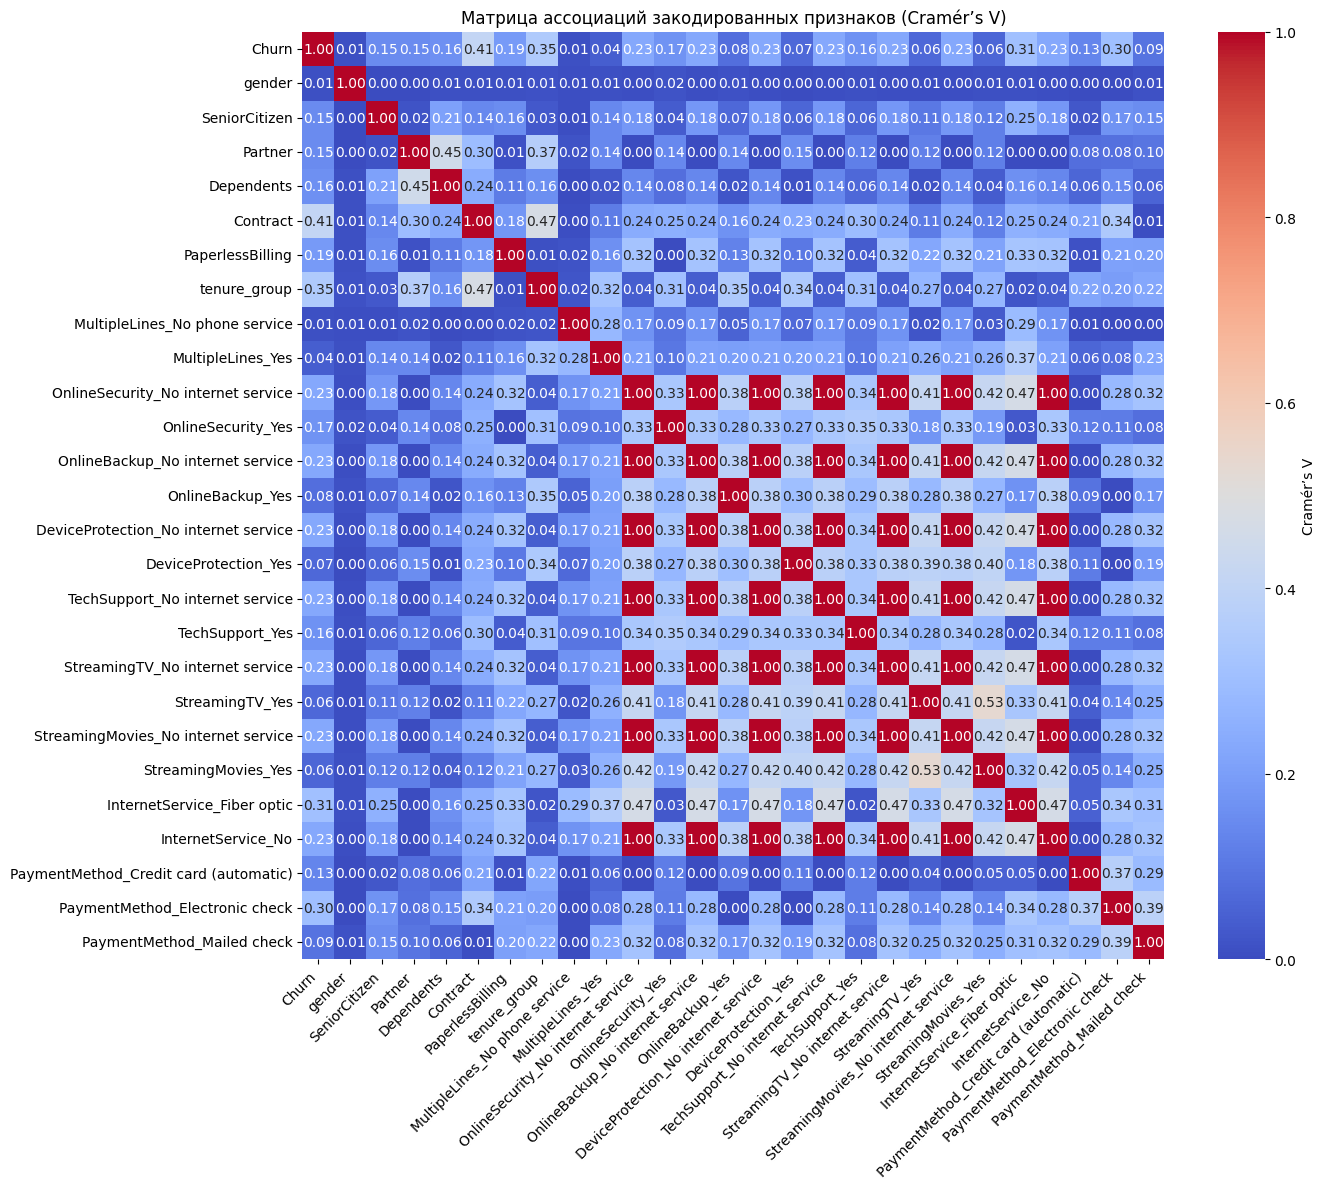

In [38]:
cols = [
    'Churn', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Contract',
    'PaperlessBilling','tenure_group',
    'MultipleLines_No phone service','MultipleLines_Yes',
    'OnlineSecurity_No internet service','OnlineSecurity_Yes',
    'OnlineBackup_No internet service','OnlineBackup_Yes',
    'DeviceProtection_No internet service','DeviceProtection_Yes',
    'TechSupport_No internet service','TechSupport_Yes',
    'StreamingTV_No internet service','StreamingTV_Yes',
    'StreamingMovies_No internet service','StreamingMovies_Yes',
    'InternetService_Fiber optic','InternetService_No',
    'PaymentMethod_Credit card (automatic)',
    'PaymentMethod_Electronic check','PaymentMethod_Mailed check'
]

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    k = min(ct.shape) - 1
    return np.sqrt((chi2 / n) / k)

V = pd.DataFrame(index=cols, columns=cols, dtype=float)
for i in cols:
    for j in cols:
        V.loc[i,j] = cramers_v(df[i], df[j])

plt.figure(figsize=(14,12))
sns.heatmap(V.astype(float), annot=True, fmt='.2f', cmap='coolwarm', cbar_kws={'label':"Cramér’s V"})
plt.title("Матрица ассоциаций закодированных признаков (Cramér’s V)")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Важно отметить, что в отличие от корреляции Пирсона, которая измеряет линейную зависимость и потому может быть отрицательной, Cramеr’s V - это мера ассоциации, которая показывает только силу, но не направление связи между категориальными переменными. Итак, здесь мы видим полную корреляцию дамми столбцов, которые несут в себе смысл отсутствия или присутствия услуги интернета. То есть все столбцы, которые заканчиваются на _No internet service полностью одинаковы и их можно удалить и оставить только 1 столбец - InternetService_No. Мы не могли раньше просто убрать категорию No internet service, потому что это была именно категория наряду с да/нет в нескольких столбцах услуг. Я считаю, что в самом начале нельзя было просто заменить ее на "No", потому что это исказило бы мнение клиентов. То есть, взять, к примеру, услугу телевидения. Человек N не имеет интернета, и, в следствие, не имеет этой услуги, и в этой строке в столбце ServiceTV было бы отмечено No internet service. Но если бы вдруг человек N захотел бы подключить интернет, никто не знает, выбрал бы он эту услугу или нет. Зато теперь, когда у нас есть фиктивные переменные, содержащие _No internet service, мы можем удалить их без потери смысла и искажения данных

In [39]:
cols_to_drop = [col for col in df.columns
                if col.endswith('_No internet service')
                and col != 'InternetService_No']

df.drop(columns=cols_to_drop, inplace=True)
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'Contract', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'tenure_group', 'MultipleLines_No phone service',
       'MultipleLines_Yes', 'OnlineSecurity_Yes', 'OnlineBackup_Yes',
       'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes',
       'StreamingMovies_Yes', 'InternetService_Fiber optic',
       'InternetService_No', 'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')

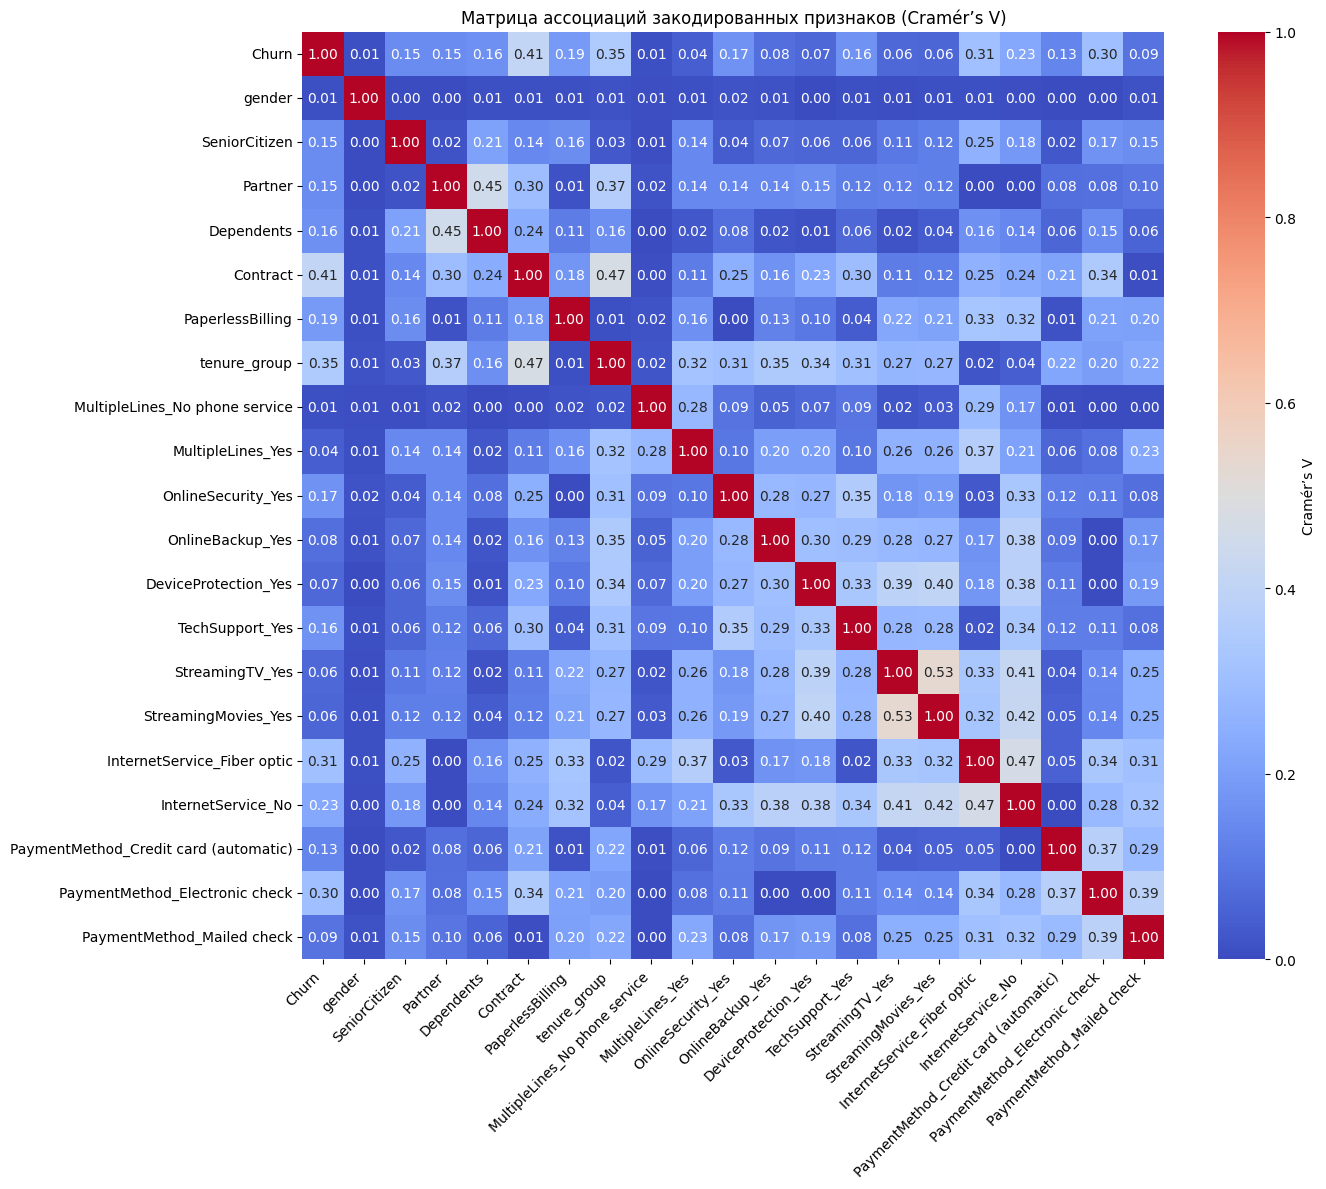

In [40]:
cols = [
    'Churn', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Contract',
    'PaperlessBilling','tenure_group',
    'MultipleLines_No phone service','MultipleLines_Yes','OnlineSecurity_Yes','OnlineBackup_Yes','DeviceProtection_Yes','TechSupport_Yes','StreamingTV_Yes','StreamingMovies_Yes',
    'InternetService_Fiber optic','InternetService_No',
    'PaymentMethod_Credit card (automatic)',
    'PaymentMethod_Electronic check','PaymentMethod_Mailed check'
]

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    k = min(ct.shape) - 1
    return np.sqrt((chi2 / n) / k)

V = pd.DataFrame(index=cols, columns=cols, dtype=float)
for i in cols:
    for j in cols:
        V.loc[i,j] = cramers_v(df[i], df[j])

plt.figure(figsize=(14,12))
sns.heatmap(V.astype(float), annot=True, fmt='.2f', cmap='coolwarm', cbar_kws={'label':"Cramér’s V"})
plt.title("Матрица ассоциаций закодированных признаков (Cramér’s V)")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Теперь между нашими категориальными признаками нет мультиколлинеарности. И чтобы окончательно узнать, нет ли ее между категориальными и непрерывными количественными признаками, и сделать это корректно, построим график специальной меры point-biserial correlation. Это тот же Пирсон, но рассчитанный так, чтобы правильно отразить, как наличие или отсутствие услуги влияет на величину платежа. Она как раз нужна, когда одна переменная категориальная и вторая непрерывная. Можем вычислить ее напрямую через функцию из scipy.stats. А вообще она высчитывается так:

для биноминального 𝑋 ∈ {0,1} и непрерывного 𝑌

$r_{pb} = \frac{\bar{Y}_1 - \bar{Y}_0}{\sigma_Y} \,\sqrt{p\,q},$


где
- $bar{Y}_1, \bar{Y}_0$ - средние значения $Y$ в группах $X=1$ и $X=0$,  
- $\sigma_Y$ - стандартное отклонение $Y$ по всей выборке,  
- $p, q$ - доли $X=1$ и $X=0$ соответственно.


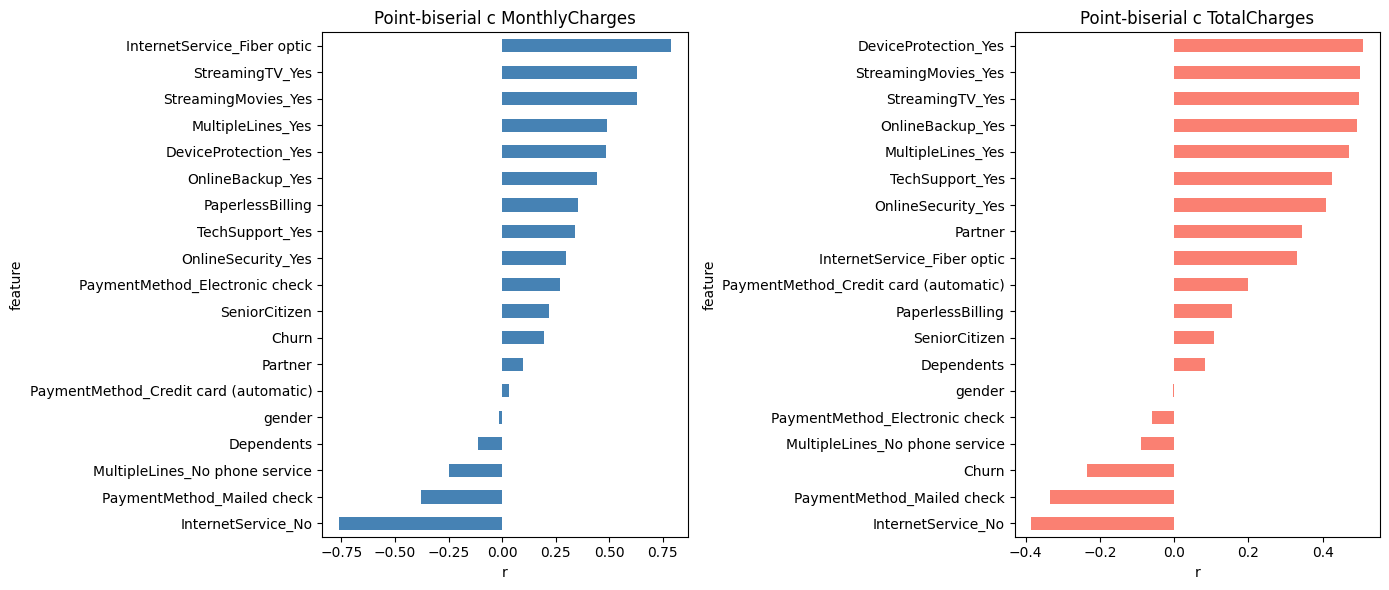

In [41]:
bin_cols = [c for c in df.columns if set(df[c].unique()) <= {0,1}]

corr_data = []
for col in bin_cols:
    r_m, _ = pointbiserialr(df[col], df['MonthlyCharges'])
    r_t, _ = pointbiserialr(df[col], df['TotalCharges'])
    corr_data.append({'feature': col, 'MonthlyCharges': r_m, 'TotalCharges': r_t})

corr_df = pd.DataFrame(corr_data).set_index('feature')

fig, axes = plt.subplots(1, 2, figsize=(14,6))

corr_df['MonthlyCharges'].sort_values().plot(
    kind='barh', ax=axes[0], color='steelblue'
)
axes[0].set_title('Point-biserial с MonthlyCharges')
axes[0].set_xlabel('r')

corr_df['TotalCharges'].sort_values().plot(
    kind='barh', ax=axes[1], color='salmon'
)
axes[1].set_title('Point-biserial с TotalCharges')
axes[1].set_xlabel('r')

plt.tight_layout()
plt.show()

Видим высокую корреляцию MonthlyCharges c InternetService_No и InternetService_Fiber optic. Это просто два дамми-признака из одной исходной категориальной переменной InternetService. Такая связь запланирована и не считается вредоносной мультиколлинеарностью, а всего лишь отражает структуру данных. Высокая корреляция с MonthlyCharges (+0.75 для Fiber, –0.75 для No) просто дает понять, что тип подключения влияет на платеж - это бизнес-зависимость, которую мы хотим сохранить, а не шум для удаления

Итак, наши данные по сути уже готовы для применения в машинном обучении, но можно еще улучшить их

# 5. Методы обучения без учителя

Чтобы улучшить данные, применим кластеризацию, РСА и поиск аномальных значений. Начнем с кластеризации - разделения всех объектов на кластеры. Это нужно, чтобы выяснить, выделяются ли в данных естественные группы клиентов с похожим поведением (набором услуг, уровнем платежей и длительностью tenure), и есть ли среди них кластеры с повышенным риском оттока

  File "C:\Users\user\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.11_3.11.2544.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

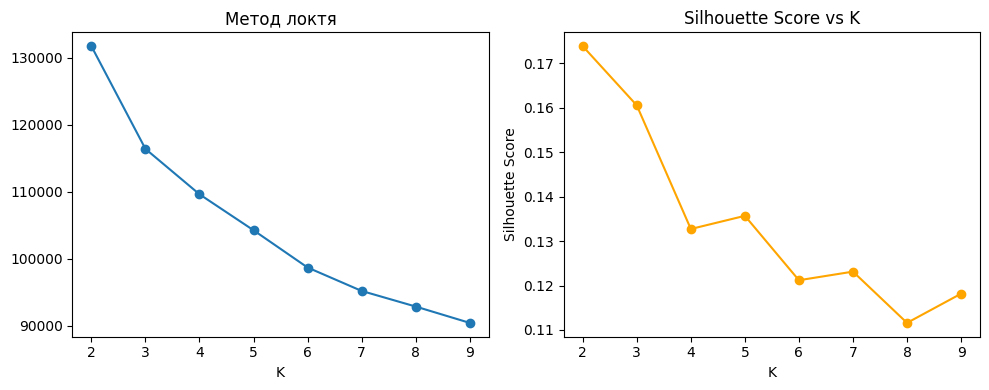

In [42]:
X = df.drop(columns=['Churn'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

K_range = range(2,10)
inertias, sil_scores = [], []

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(K_range, inertias, '-o')
plt.title('Метод локтя')
plt.xlabel('K')

plt.subplot(1,2,2)
plt.plot(K_range, sil_scores, '-o', color='orange')
plt.title('Silhouette Score vs K')
plt.xlabel('K')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()



По методу локтя точки сгиба как таковой не видно, по графику силуэта самые большие значения - это 2 и 3. Скорее всего, лучшее количество кластеров это 3.

In [43]:
k_opt = 3
kmeans = KMeans(n_clusters=k_opt, random_state=42).fit(X_scaled)
df['cluster_label'] = kmeans.labels_

Дальше узнаем процент ушедших клиентов в каждом из кластеров

In [44]:
churn_by_cluster = (
    df.groupby('cluster_label')['Churn']
      .mean()
      .mul(100)
      .round(1)
)
print("Churn rate (%) по кластерам:\n", churn_by_cluster)


Churn rate (%) по кластерам:
 cluster_label
0    15.6
1    47.8
2     7.7
Name: Churn, dtype: float64


Видим, что во второй группе ушло целых 48% людей, это почти половина, значит, это самая рисковая группа клиентов для компании. На ее месте, я бы сделала упор на удержании именно таких пользователей

Для визуализации используем РСА и возьмем первые три компоненты

In [45]:
pca = PCA(n_components=3, random_state=42)
pcs = pca.fit_transform(X_scaled)
explained3 = pca.explained_variance_ratio_
print(f"Объясненная вариация: PC1={explained3[0]:.2f}, PC2={explained3[1]:.2f}, PC3={explained3[2]:.2f}, total={explained3.sum():.2f}")

Объясненная вариация: PC1=0.26, PC2=0.15, PC3=0.07, total=0.48


Они объясняют 48% дисперсии данных. Итак, сначала покажем разделение по оттоку

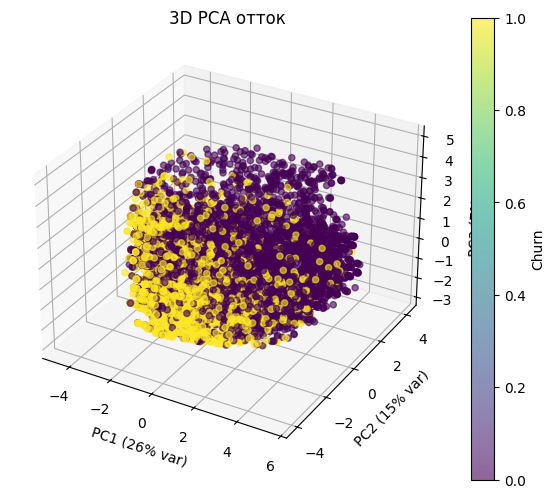

In [46]:
fig = plt.figure(figsize=(7,6))
ax = fig.add_subplot(111, projection='3d')
df['PC1'] = pcs[:, 0]
df['PC2'] = pcs[:, 1]
df['PC3'] = pcs[:, 2]
scatter = ax.scatter(pcs[:, 0], pcs[:, 1], pcs[:, 2],
                     c=df['Churn'], alpha=0.6)


ax.set_title('3D PCA отток')
ax.set_xlabel(f'PC1 ({explained3[0]:.0%} var)')
ax.set_ylabel(f'PC2 ({explained3[1]:.0%} var)')
ax.set_zlabel(f'PC3 ({explained3[2]:.0%} var)')
fig.colorbar(scatter, label='Churn')
plt.show()

А теперь по кластерам

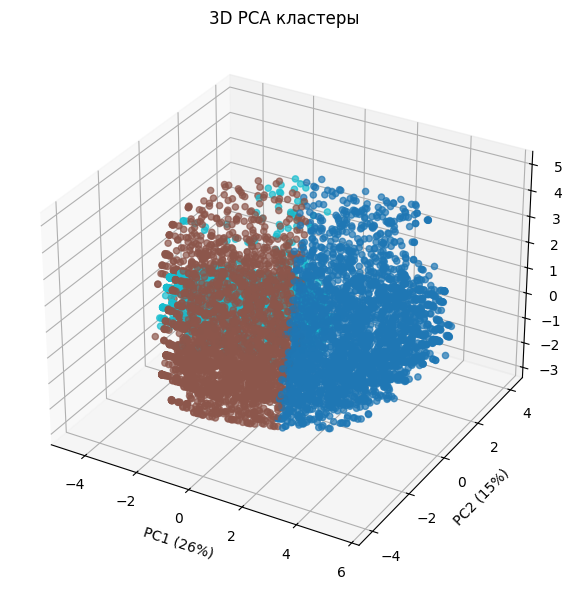

In [47]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')


for churn_val in [0,1]:
    subset = df[df['Churn']==churn_val]
    ax.scatter(
        subset['PC1'], subset['PC2'], subset['PC3'],
        c=subset['cluster_label'],
        cmap='tab10',
        alpha=0.7
    )

ax.set_title('3D PCA кластеры')
ax.set_xlabel(f'PC1 ({explained3[0]:.0%})')
ax.set_ylabel(f'PC2 ({explained3[1]:.0%})')
ax.set_zlabel(f'PC3 ({explained3[2]:.0%})')
plt.tight_layout()
plt.show()


Итак, мы видим, что в коричневом кластере сосредоточены клиенты, которые ушли (на прошлом графике это желтый цвет), и, похоже, что это и есть тот самый кластер, в котором ушло 48% клиентов

Выявленные кластеры действительно хорошо разделяются в пространстве наиболее вариативных направлений. В этом мы и убедились, применив PCA и построив проекции данных на первые три главные компоненты. Однако для финального обучения моделей я не буду использовать PCA-признаки, а оставлю исходные. PCA в нашем случае служит только инструментом EDA и визуальной проверки качества кластеризации, но не входит в подготовку данных для модели. PCA создает линейные комбинации исходных признаков, и в результате PC-компоненты теряют прямой бизнес-смысл. В нашей задаче важно понимать, какие конкретно услуги или паттерны поведения влияют на отток, а PCA-признаки дают лишь абстрактные направления. Если захочется выяснить, как модель влияет на бизнес-показатели (например, на сколько упадет отток при отключении услуги X), PCA усложнит такие расчеты, поскольку надо делать обратное преобразование компонент в исходные признаки, что не всегда удобно

Теперь поищем аномалии в наших данных

In [48]:
X_unlab = X_scaled

iso = IsolationForest(contamination=0.05, random_state=42)
iso_labels = iso.fit_predict(X_unlab)

df['is_anomaly'] = (iso_labels == -1).astype(int)

anomaly_churn = df.groupby('is_anomaly')['Churn'].mean().mul(100).round(1)
print("процент ушедших клиентов\n", anomaly_churn, "%\n")

процент ушедших клиентов
 is_anomaly
0    27.1
1    16.5
Name: Churn, dtype: float64 %



IsolationForest выделил 0 - не аномалия, 1 - аномалия, и клиенты, которых он посчитал аномальными, уходят реже, чем среднестатистические!

IsolationForest ищет объекты, наиболее удаленные от «центра тяжести» данных в многомерном признаковом пространстве. Он не знает о целевой переменной Churn, а только об особенностях входных данных. Поэтому в нашем случае он выделил в качестве аномалий тех клиентов, кто выглядел необычно по совокупности признаков.
Например, у кого-то очень высокие суммарные начисления вместе с длительным сроком обслуживания, или нетипичные сочетания большого числа подключенных сервисов, или, наоборот, пользователи со странным набором услуг (много дополнительных опций при самом коротком контракте)

Такие клиенты оказываются вне основного облака данных, и IsolationForest относит их к аномалиям. Но именно эти необычные сочетания признаков, по сути, сигнализируют о ценных пользователях или корпоративных аккаунтах, которые, несмотря на свою экзотичность, очень лояльны и редко уходят. Возможно, именно поэтому в группе аномалий мы видим ниже средний churn

Теперь наши данные готовы к машинному обучению

# 6. Модели машинного обучения. Применение обработанных данных

Разобьем нашу выборку на тестовую и обучающую

In [49]:
df['Churn'].value_counts(normalize=True).round(2) * 100

Churn
0    73.0
1    27.0
Name: proportion, dtype: float64

У нас есть дисбаланс классов. Churn = 1 - это 27% от всех решений клиентов. Поэтому при разбиении выборки применим стратификацию, которая сохранит такое соотношение классов. Разбивать выборку будем случайно, потому что у нас нет никаких временных зависимостей

In [50]:
# служебные столбцы из раздела 5 (кластеры, главные компоненты, аномалии) в модель не берем:
# они были получены на всех данных, включая будущую тестовую выборку, и это была бы утечка данных
X = df.drop(columns=['Churn', 'cluster_label', 'PC1', 'PC2', 'PC3', 'is_anomaly'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Обучим модели. Возьмем 7 разных, это будут:
1. Логистическая регрессия
2. Многослойный перцептрон
3. Случайный лес
4. Градиентный бустинг
5. KNN
6. SVM
7. Наивный байес

Будем замерять время обучения, а также применим кросс-валидацию, чтобы узнать точные метрики качества моделей. Будем использовать такие метрики, как accuracy, precision, recall, f1 и roc-auc, после соберем все в таблицу. Но чтобы оценить результаты полностью, также возьмем изначальный датасет, применим к нему минимальные изменения, чтобы модели смогли обучиться, и обучим их уже на этих сырых данных. После этого сравним, насколько помогла наша обширная предобработка

In [51]:
def res(X_train, y_train, X_test, y_test):
    models = {
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(random_state=42))
    ]),
    'MLPClassifier': MLPClassifier(random_state=42, hidden_layer_sizes=(10, 10)),
    'RandomForest': RandomForestClassifier(random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_jobs=-1))
    ]),
    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(probability=True, random_state=42))
    ]),
    'GaussianNB': GaussianNB()
    }
    scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
    cv_results = []

    for name, model in models.items():
        scores = cross_validate(model, X_train, y_train, cv=5,
                                scoring=scoring, return_train_score=False,
                                n_jobs=-1)

        cv_mean = {metric: np.mean(scores[f'test_{metric}']) for metric in scoring}

        start_fit = time.time()
        model.fit(X_train, y_train)
        fit_time = time.time() - start_fit

        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
        test_metrics = {
            'accuracy': np.mean(y_pred == y_test),
            'precision': np.sum((y_pred == 1) & (y_test == 1)) / max(np.sum(y_pred == 1), 1),
            'recall': np.sum((y_pred == 1) & (y_test == 1)) / max(np.sum(y_test == 1), 1),
            'f1': 2 * np.sum((y_pred == 1) & (y_test == 1)) / max(np.sum(y_pred == 1) + np.sum(y_test == 1), 1),
            'roc_auc': roc_auc_score(y_test, y_proba)
        }

        row = {
            'model': name,
            'fit_time_sec': fit_time
        }
        row.update({f'train_{k}': v for k, v in cv_mean.items()})
        row.update({f'test_{k}': v for k, v in test_metrics.items()})

        cv_results.append(row)

    results_df = pd.DataFrame(cv_results).set_index('model')
    return results_df

In [52]:
data = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df2 = pd.DataFrame(data)
df2['TotalCharges'] = pd.to_numeric(df2['TotalCharges'], errors='coerce')
df2.drop(columns=['customerID'], inplace=True)
df2.dropna(inplace=True)

In [53]:
colsbin = ['gender', 'Partner', 'Dependents', 'PaperlessBilling', 'Churn', 'PhoneService']
cols3unique = [
    'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
le = LabelEncoder()
for col in colsbin:
    df2[col] = le.fit_transform(df2[col])
df2 = pd.get_dummies(df2, columns=cols3unique + ['InternetService', 'Contract', 'PaymentMethod'], drop_first=False)

In [54]:
X2 = df2.drop(columns=['Churn'])
y2 = df2['Churn']
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42,stratify=y2)
print('До качественной предобработки')
res(X2_train, y2_train, X2_test, y2_test)

До качественной предобработки


,fit_time_sec,train_accuracy,train_precision,train_recall,train_f1,train_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,,,,
LogisticRegression,0.041172,0.802311,0.653247,0.548495,0.596059,0.845965,0.803838,0.647590,0.574866,0.609065,0.835559
MLPClassifier,0.372818,0.789156,0.639000,0.509699,0.554075,0.819756,0.799574,0.629944,0.596257,0.612637,0.841093
RandomForest,0.272175,0.788267,0.627565,0.498997,0.555847,0.820789,0.783227,0.619377,0.478610,0.539970,0.813538
GradientBoosting,1.365113,0.801244,0.660889,0.519732,0.581722,0.845676,0.796020,0.640777,0.529412,0.579795,0.838475
KNN,0.013638,0.762667,0.556969,0.521739,0.538723,0.772593,0.742715,0.515873,0.521390,0.518617,0.769745
SVM,8.880488,0.798044,0.659264,0.501003,0.569040,0.796964,0.788202,0.624183,0.510695,0.561765,0.788965
GaussianNB,0.010323,0.696356,0.461526,0.848829,0.597831,0.821901,0.681592,0.447293,0.839572,0.583643,0.807470


In [55]:
print('После качественной предобработки')
res(X_train, y_train, X_test, y_test)

После качественной предобработки


,fit_time_sec,train_accuracy,train_precision,train_recall,train_f1,train_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,,,,
LogisticRegression,0.033376,0.806044,0.673414,0.525753,0.590259,0.849687,0.793888,0.634615,0.529412,0.577259,0.836504
MLPClassifier,1.523182,0.800356,0.673602,0.484950,0.563572,0.847739,0.798863,0.654237,0.516043,0.576981,0.838279
RandomForest,0.285825,0.787022,0.628502,0.484950,0.547425,0.824437,0.788202,0.629252,0.494652,0.553892,0.821439
GradientBoosting,1.174773,0.799644,0.658895,0.511706,0.575933,0.845164,0.793888,0.631250,0.540107,0.582133,0.840654
KNN,0.002010,0.767289,0.571003,0.500334,0.533301,0.770716,0.754797,0.539726,0.526738,0.533153,0.770425
SVM,6.978533,0.798400,0.672289,0.474247,0.555947,0.799444,0.795309,0.652482,0.491979,0.560976,0.784693
GaussianNB,0.003017,0.767644,0.545048,0.756522,0.633523,0.836809,0.745558,0.514652,0.751337,0.610870,0.828666


Сравнивая результаты моделей на обработанных данных и на исходном датасете с минимальной обработкой, видно, что качество предсказаний почти не изменилось. Например, у логистической регрессии roc-auc на тесте 0.836 до предобработки и 0.837 после, у градиентного бустинга 0.838 и 0.841. Где-то метрики немного выросли, а где-то немного упали: у той же логистической регрессии f1 на тесте снизился с 0.61 до 0.58, а recall с 0.57 до 0.53. Такие небольшие различия могут появиться просто из-за другого случайного разбиения выборки, поэтому нельзя сказать, что одна версия данных однозначно лучше другой. Заметно выиграл только наивный байес (roc-auc вырос с 0.81 до 0.83, f1 с 0.58 до 0.61). Вероятно, это связано с тем, что он сильнее остальных моделей зависит от распределения признаков, а мы сделали распределение TotalCharges более симметричным и убрали дублирующие друг друга столбцы.

Получается, что основная ценность предобработки здесь не в росте метрик. Удаление избыточных столбцов, аккуратная обработка значений 'No internet service' и преобразование TotalCharges сделали данные чище и понятнее для интерпретации, но сам сигнал об оттоке в данных остался тем же, и модели находят его одинаково хорошо в обоих вариантах. Для этого датасета это ожидаемо: исходные признаки и так достаточно информативны и почти не содержат шума. Время обучения в обоих случаях тоже примерно одинаковое: дольше всего обучается SVM (7-9 секунд), остальные модели укладываются в пару секунд.

Recall и precision, конечно, хотелось бы видеть поближе к единице. Но как показала практика, в реальной задаче добиться таких значений не получается. В нашем случае отток встречается примерно у четверти клиентов, и поднять recall и precision до идеала тяжело. Значения около 0.6 уже говорят о том, что модель неплохо справляется с задачей. Она умеет находить около половины ушедших и при этом не слишком сильно ошибается. В таких условиях можно оценить roc-auc либо f1, который учитывает баланс между полнотой и точностью.

Что касается accuracy, то она изменяется менее заметно по сравнению с F1 или ROC-AUC. Возможно, это связано с тем, что отток в нашем случае событие довольно редкое, ведь, как мы уже сказали, только около 27 % клиентов уходят, а accuracy как раз во многом зависит от баланса классов. Модель может добиться хорошей точности просто за счет правильной классификации большинства оставшихся клиентов, при этом хуже распознавая тех, кто реально уходит. И это, к тому же, может послужить примером того, почему важно смотреть и на precision, recall и F1 так же внимательно. Лучшими по roc-auc на тесте оказались градиентный бустинг, многослойный перцептрон и логистическая регрессия (около 0.84), причем логистическая регрессия обучается быстрее всех и проще всех интерпретируется.
